# Exercise 10.1 — First eigenvalue of a (symmetric) matrix: Newton + Gradient

We minimize
$$
\lambda_1 = \min_{\|x\|=1} x^\top A x
$$
by using the constraint $h(x) = 1 - \|x\|^2 = 0$ and the Lagrangian
$$
L(x,\mu) = f(x) + \mu h(x), \qquad f(x) = x^\top A x.
$$

## (a) Stationary points are eigenpairs
$$
\nabla_x L(x,\mu) = 2Ax - 2\mu x = 0
\iff Ax = \mu x.
$$
With $h(x) = 0$, $x$ is a unit eigenvector and $\mu$ the corresponding eigenvalue.

## (b) Derivatives
$$
\nabla_x L(x,\mu) = 2(A - \mu I)x, \quad
\nabla_x^2 L(x,\mu) = 2(A - \mu I),
$$
$$
\partial_\mu \nabla_x L(x,\mu) = -2x, \quad
\nabla h(x) = -2x.
$$

Define
$$
F(x,\mu) =
\begin{pmatrix}
\nabla_x L(x,\mu) \\
h(x)
\end{pmatrix}
=
\begin{pmatrix}
2(A - \mu I)x \\
1 - \|x\|^2
\end{pmatrix}.
$$
Then the Jacobian is
$$
J(x,\mu) =
\begin{pmatrix}
2(A - \mu I) & -2x \\
-2x^\top & 0
\end{pmatrix}.
$$

## (c) Newton step
Solve
$$
J(x,\mu)
\begin{pmatrix}
\Delta x \\
\Delta \mu
\end{pmatrix}
= -F(x,\mu)
$$
and set
$$
(x,\mu) \leftarrow (x,\mu) + (\Delta x, \Delta \mu),
$$
then renormalize $x$.

## (d) Gradient method for Rayleigh quotient
For
$$
\phi(x) = \frac{x^\top A x}{x^\top x},
$$
$$
\nabla \phi(x) =
\frac{2}{x^\top x} \bigl(Ax - \phi(x)x\bigr).
$$
Use backtracking to pick $s_n \in (0,1]$ such that
$$
\phi(x_n - s_n \nabla \phi(x_n)) < \phi(x_n).
$$

(Background: Newton/gradient methods are discussed in the provided lecture notes.)

A (used) =
 [[1.  1.5 3. ]
 [1.5 2.  1. ]
 [3.  1.  1. ]]

np.linalg.eig eigenvalues (sorted) = [-2.03553391  1.          5.03553391]

Gradient descent result (approx smallest):
  mu = -2.035533905932738
  x  = [-0.72396274  0.0999584   0.68255862]
  residual ||Ax-mu x|| = 6.398270009375547e-11

Newton refinement (started from gradient solution):
  mu = -2.0355339059327378
  x  = [-0.72396274  0.0999584   0.68255862]
  residual ||Ax-mu x|| = 3.1401849173675503e-16

Smallest eigenpair from np.linalg.eig:
  mu = -2.0355339059327378
  x  = [-0.72396274  0.0999584   0.68255862]


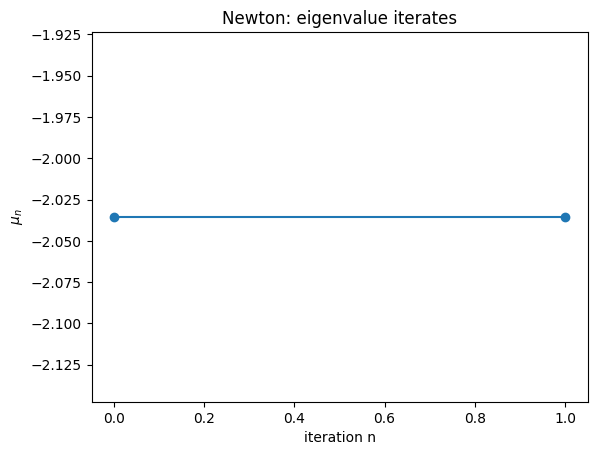

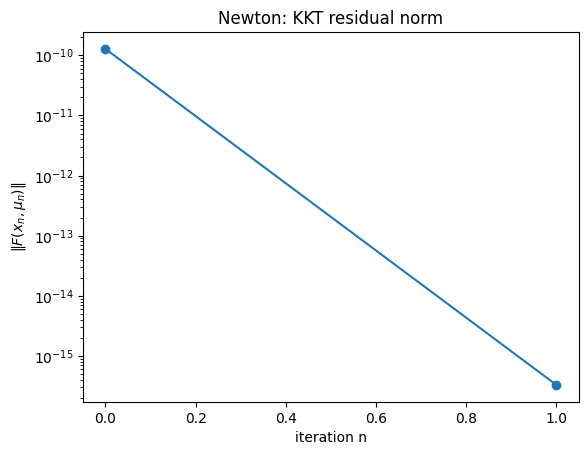

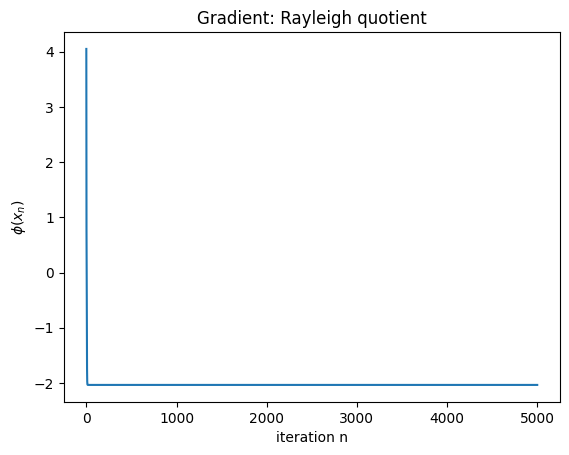

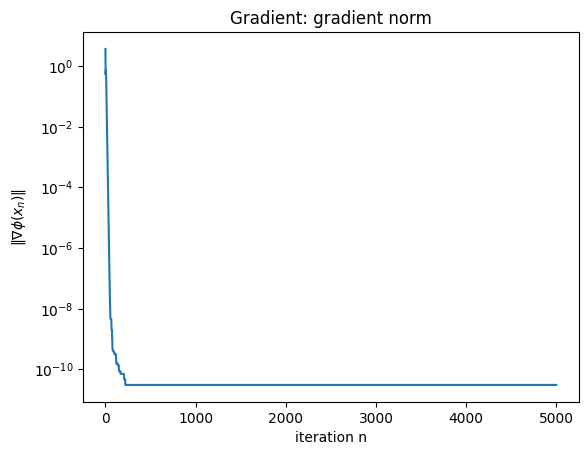


A few normalized iterates x_n/||x_n|| (gradient):
  n=0: [0.36353657 0.86429949 0.34760259]
  n=1: [-0.5879753   0.69910542 -0.40686196]
  n=2: [-0.5662944   0.7808456  -0.26380067]
  n=3: [-0.59393622  0.79364013 -0.13181468]
  n=4: [-0.64967861  0.76017958  0.00668638]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Helpers
def rayleigh(A, x):
    x = np.asarray(x, dtype=float)
    return float(x @ (A @ x) / (x @ x))

def grad_rayleigh(A, x):
    x = np.asarray(x, dtype=float)
    denom = x @ x
    fx = rayleigh(A, x)
    return (2.0 / denom) * (A @ x - fx * x)

# (c) Newton on KKT system F(x,mu)=0
def newton_eigpair(A, x0, mu0=None, maxit=50, tol=1e-14, damp=True):
    """
    Newton method on F(x,mu) = [2(A-muI)x; 1-||x||^2] = 0.
    Local method: converges to the eigenpair near the initial guess.
    """
    A = np.asarray(A, dtype=float)
    n = A.shape[0]
    I = np.eye(n)

    x = np.array(x0, dtype=float).copy()
    if np.linalg.norm(x) == 0:
        x[0] = 1.0
    x /= np.linalg.norm(x)

    mu = rayleigh(A, x) if mu0 is None else float(mu0)

    hist = {"F_norm": [], "mu": [], "x": []}

    for k in range(maxit):
        Fx = 2.0 * (A - mu * I) @ x
        Fh = 1.0 - x @ x
        F = np.concatenate([Fx, [Fh]])
        Fn = np.linalg.norm(F)

        hist["F_norm"].append(Fn)
        hist["mu"].append(mu)
        hist["x"].append(x.copy())

        if Fn < tol:
            break

        J11 = 2.0 * (A - mu * I)
        J12 = (-2.0 * x).reshape(-1, 1)
        J21 = (-2.0 * x).reshape(1, -1)
        J22 = np.array([[0.0]])
        J = np.block([[J11, J12],
                      [J21, J22]])

        rhs = -F
        try:
            step = np.linalg.solve(J, rhs)
        except np.linalg.LinAlgError:
            step, *_ = np.linalg.lstsq(J, rhs, rcond=None)

        dx = step[:n]
        dmu = step[n]

        if damp:
            # simple backtracking on ||F||
            alpha = 1.0
            for _ in range(25):
                x_try = x + alpha * dx
                if np.linalg.norm(x_try) == 0:
                    alpha *= 0.5
                    continue
                x_try /= np.linalg.norm(x_try)
                mu_try = mu + alpha * dmu

                Fx_try = 2.0 * (A - mu_try * I) @ x_try
                Fh_try = 1.0 - x_try @ x_try
                F_try = np.concatenate([Fx_try, [Fh_try]])

                if np.linalg.norm(F_try) < Fn:
                    x, mu = x_try, mu_try
                    break
                alpha *= 0.5
            else:
                x = x + dx
                x /= np.linalg.norm(x)
                mu = mu + dmu
        else:
            x = x + dx
            x /= np.linalg.norm(x)
            mu = mu + dmu

    return mu, x, hist

# (d) Gradient descent on Rayleigh quotient
def gradient_rayleigh_min(A, x0, maxit=5000, tol=1e-12, c=1e-4):
    """
    Gradient descent on phi(x)=Rayleigh(A,x) with backtracking Armijo-like condition.
    """
    A = np.asarray(A, dtype=float)
    x = np.array(x0, dtype=float).copy()
    if np.linalg.norm(x) == 0:
        x[0] = 1.0

    hist = {"phi": [], "grad_norm": [], "x_unit": []}

    for k in range(maxit):
        phi0 = rayleigh(A, x)
        g = grad_rayleigh(A, x)
        gn = np.linalg.norm(g)

        hist["phi"].append(phi0)
        hist["grad_norm"].append(gn)
        hist["x_unit"].append(x / np.linalg.norm(x))

        if gn < tol:
            break

        s = 1.0
        for _ in range(30):
            x_try = x - s * g
            if np.linalg.norm(x_try) == 0:
                s *= 0.5
                continue
            phi_try = rayleigh(A, x_try)
            # sufficient decrease
            if phi_try < phi0 - c * s * (gn**2):
                x = x_try
                break
            s *= 0.5
        else:
            x = x - 1e-6 * g

    return rayleigh(A, x), x / np.linalg.norm(x), hist

# (e) Test on the given matrix
A = np.array([[1, 2, 3],
              [1, 2, 1],
              [3, 1, 1]], dtype=float)

# The exercise says "symmetric"; the provided matrix isn't symmetric.
# To follow the exercise statement, we symmetrize it:
A = 0.5 * (A + A.T)

# Reference eigenpairs
w, V = np.linalg.eig(A)
idx = np.argsort(w.real)
w_sorted = w.real[idx]
vmin = V[:, idx[0]].real
vmin /= np.linalg.norm(vmin)

print("A (used) =\n", A)
print("\nnp.linalg.eig eigenvalues (sorted) =", w_sorted)

# Gradient method typically finds the smallest eigenpair (global-ish on Rayleigh quotient)
rng = np.random.default_rng(1)
x0 = rng.normal(size=A.shape[0])
muG, xG, histG = gradient_rayleigh_min(A, x0=x0)

# Use gradient result as initial guess for Newton to refine *that* eigenpair
muN, xN, histN = newton_eigpair(A, x0=xG, mu0=muG, maxit=30, tol=1e-15, damp=True)

# Align signs for nicer comparison
def align(u, v): return u if (u @ v) >= 0 else -u
xG = align(xG, vmin)
xN = align(xN, vmin)

print("\nGradient descent result (approx smallest):")
print("  mu =", muG)
print("  x  =", xG)
print("  residual ||Ax-mu x|| =", np.linalg.norm(A @ xG - muG * xG))

print("\nNewton refinement (started from gradient solution):")
print("  mu =", muN)
print("  x  =", xN)
print("  residual ||Ax-mu x|| =", np.linalg.norm(A @ xN - muN * xN))

print("\nSmallest eigenpair from np.linalg.eig:")
print("  mu =", w_sorted[0])
print("  x  =", vmin)

# ----------------------------
# Plots requested
# ----------------------------
plt.figure()
plt.plot(histN["mu"], marker="o")
plt.xlabel("iteration n")
plt.ylabel(r"$\mu_n$")
plt.title("Newton: eigenvalue iterates")
plt.show()

plt.figure()
plt.semilogy(histN["F_norm"], marker="o")
plt.xlabel("iteration n")
plt.ylabel(r"$\|F(x_n,\mu_n)\|$")
plt.title("Newton: KKT residual norm")
plt.show()

plt.figure()
plt.plot(histG["phi"])
plt.xlabel("iteration n")
plt.ylabel(r"$\phi(x_n)$")
plt.title("Gradient: Rayleigh quotient")
plt.show()

plt.figure()
plt.semilogy(histG["grad_norm"])
plt.xlabel("iteration n")
plt.ylabel(r"$\|\nabla\phi(x_n)\|$")
plt.title("Gradient: gradient norm")
plt.show()

print("\nA few normalized iterates x_n/||x_n|| (gradient):")
for k in range(min(5, len(histG["x_unit"]))):
    print(f"  n={k}: {histG['x_unit'][k]}")


# Exercise 10.2 — Closest symmetric matrix (Lagrange–Newton), case $n=2$

We solve
$$
\min_{S\in\mathbb{R}^{n\times n},\, S=S^\top}\ \|S-A\|_F^2.
$$
Introduce the constraint
$$
h(S)=S^\top-S=0,
$$
and Lagrangian (matrix multiplier $\mu\in\mathbb{R}^{n\times n}$)
$$
L(S,\mu)=\|S-A\|_F^2 + \langle S^\top-S,\mu\rangle,
\qquad \langle X,Y\rangle=\mathrm{tr}(X^\top Y).
$$

## (a) Derivatives
$$
\nabla_S L(S,\mu)=2(S-A)+\mu^\top-\mu,
$$
$$
\nabla_S^2L(S,\mu)[\Delta S]=2\,\Delta S,
\qquad
dh(S)[\Delta S]=\Delta S^\top-\Delta S.
$$

## (b) Newton system for $F(S,\mu)=0$
Define
$$
F(S,\mu)=\begin{pmatrix}\nabla_S L(S,\mu)\\ h(S)\end{pmatrix}.
$$
With $\mathrm{vec}(\cdot)$ (column stacking) and the commutation matrix $K$ such that
$\mathrm{vec}(X^\top)=K\,\mathrm{vec}(X)$, the Jacobian becomes
$$
J=\begin{pmatrix}
2I & (K-I)\\
(K-I) & 0
\end{pmatrix}.
$$
Since $J$ may be singular, we use `np.linalg.pinv` and make **damped** Newton steps.

## (c) Convergence plots
We plot $\|\nabla_S L(S_n,\mu_n)\|_F$ and $\|h(S_n)\|_F$.

## (d) Test
$$
A=\begin{pmatrix}10&2\\1&0\end{pmatrix},\quad S_0=I,\quad \mu_0=0.
$$
The true closest symmetric matrix is the projection
$$
S^\star=\tfrac12(A+A^\top).
$$

(Reference: exercise statement in the provided script.)

A =
 [[10.  2.]
 [ 1.  0.]]

Computed S* =
 [[1.00000000e+01 1.50000000e+00]
 [1.50000000e+00 2.22044605e-16]]

Projection (A + A^T)/2 =
 [[10.   1.5]
 [ 1.5  0. ]]

||S* - (A+A^T)/2||_F = 6.661338147750939e-16


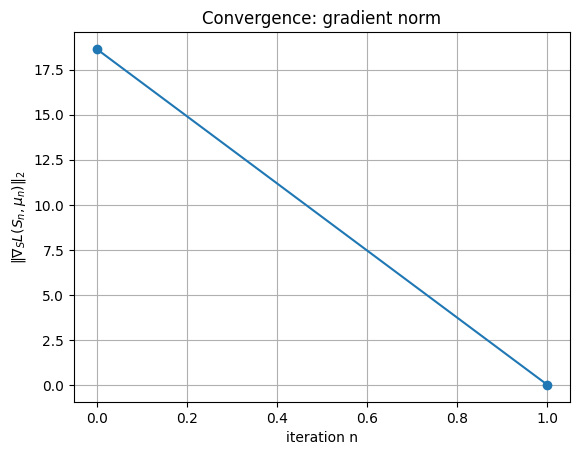

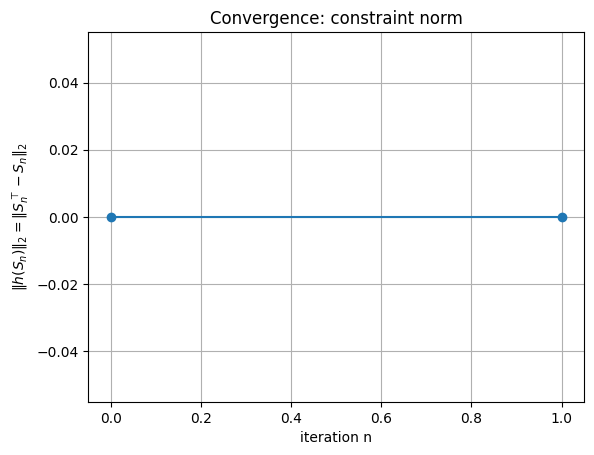

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------
# Helpers: vec/unvec (column-major) and commutation matrix
# ----------------------------
def vec(M):
    return M.reshape(-1, order="F")

def unvec(v, n):
    return v.reshape((n, n), order="F")

def commutation_matrix(n):
    K = np.zeros((n*n, n*n))
    for i in range(n):
        for j in range(n):
            e_ij = i + j*n
            e_ji = j + i*n
            K[e_ji, e_ij] = 1.0
    return K

# ----------------------------
# Lagrangian pieces
# ----------------------------
def grad_L(A, S, mu):
    return 2.0*(S - A) + (mu.T - mu)

def h(S):
    return S.T - S

def F(A, S, mu):
    return np.concatenate([vec(grad_L(A, S, mu)), vec(h(S))])

def J_matrix(n):
    I = np.eye(n*n)
    K = commutation_matrix(n)
    Z = np.zeros((n*n, n*n))
    return np.block([[2*I, (K-I)],
                     [(K-I), Z]])

# ----------------------------
# Damped pseudo-Newton with correct "abort if no change" logic
# ----------------------------
def lagrange_newton_closest_symmetric(A, S0, mu0, maxit=50, tol_F=1e-12, tol_change=1e-15):
    A = np.asarray(A, float)
    n = A.shape[0]
    S = np.array(S0, float).copy()
    mu = np.array(mu0, float).copy()

    J = J_matrix(n)
    Jpinv = np.linalg.pinv(J)

    # store norms (explicit 2-norm of vec)
    g_norms = []
    h_norms = []

    for k in range(maxit):
        gk = np.linalg.norm(vec(grad_L(A, S, mu)), 2)
        hk = np.linalg.norm(vec(h(S)), 2)
        g_norms.append(gk)
        h_norms.append(hk)

        # convergence of F (optional, but good)
        if np.linalg.norm(F(A, S, mu), 2) < tol_F:
            break

        # Newton direction (minimum-norm solution)
        step = -Jpinv @ F(A, S, mu)
        dS = unvec(step[:n*n], n)
        dmu = unvec(step[n*n:], n)

        # damping by backtracking on merit m = ||g||_2^2 + ||h||_2^2
        merit = gk**2 + hk**2
        alpha = 1.0
        for _ in range(30):
            S_try = S + alpha*dS
            mu_try = mu + alpha*dmu
            g_try = np.linalg.norm(vec(grad_L(A, S_try, mu_try)), 2)
            h_try = np.linalg.norm(vec(h(S_try)), 2)
            merit_try = g_try**2 + h_try**2
            if merit_try < merit:
                S, mu = S_try, mu_try
                break
            alpha *= 0.5
        else:
            # if backtracking fails, take a tiny step
            S = S + 1e-6*dS
            mu = mu + 1e-6*dmu

        # ---- (c) abort when BOTH values do not change anymore (after update)
        g_new = np.linalg.norm(vec(grad_L(A, S, mu)), 2)
        h_new = np.linalg.norm(vec(h(S)), 2)
        if abs(g_new - gk) < tol_change and abs(h_new - hk) < tol_change:
            # append the post-update values so plot shows the "flat" end
            g_norms.append(g_new)
            h_norms.append(h_new)
            break

    return S, mu, np.array(g_norms), np.array(h_norms)

# ----------------------------
# (d) Test case exactly as stated
# ----------------------------
A = np.array([[10, 2],
              [ 1, 0]], dtype=float)
S0 = np.array([[1, 0],
               [0, 1]], dtype=float)
mu0 = np.zeros((2,2), dtype=float)

S_star, mu_star, g_hist, h_hist = lagrange_newton_closest_symmetric(
    A, S0=S0, mu0=mu0, maxit=50, tol_F=1e-14, tol_change=1e-15
)

S_proj = 0.5*(A + A.T)

print("A =\n", A)
print("\nComputed S* =\n", S_star)
print("\nProjection (A + A^T)/2 =\n", S_proj)
print("\n||S* - (A+A^T)/2||_F =", np.linalg.norm(S_star - S_proj, "fro"))

# ----------------------------
# (c) Plots (linear scale to avoid log(0) issues)
# ----------------------------
plt.figure()
plt.plot(g_hist, marker="o")
plt.xlabel("iteration n")
plt.ylabel(r"$\|\nabla_S L(S_n,\mu_n)\|_2$")
plt.title("Convergence: gradient norm")
plt.grid(True)
plt.show()

plt.figure()
plt.plot(h_hist, marker="o")
plt.xlabel("iteration n")
plt.ylabel(r"$\|h(S_n)\|_2 = \|S_n^\top-S_n\|_2$")
plt.title("Convergence: constraint norm")
plt.grid(True)
plt.show()

# Exercise 10.3 — Quasi-Newton methods (Broyden + symmetric update)

We want to find roots of $F:\mathbb{R}^n\to\mathbb{R}^n$ via
$$
H_n \Delta x_n = -F(x_n),\qquad x_{n+1}=x_n+\Delta x_n,
$$
with $H_n\approx DF(x_n)$.

## (a) Two quasi-Newton updates

### Classical Broyden (rank-1)
Let $s:=x_{n+1}-x_n$ and $y:=F(x_{n+1})-F(x_n)$.  
Imposing the secant condition $H_{n+1}s=y$ and minimizing $\|H_{n+1}-H_n\|_F$
gives (lecture notes eq. (6.22))
$$
H_{n+1}=H_n+\frac{(y-H_ns)s^\top}{\|s\|_2^2}.
$$

### Symmetric update (PSB / exercise eq. (3))
With $u:=y-H_ns$ and $\alpha:=\|s\|_2^2$,
$$
H_{n+1}=H_n+\frac{u s^\top+s u^\top}{\alpha}-\frac{(u^\top s)}{\alpha^2}\, s s^\top.
$$

## (b) Test Broyden on the lecture example
We use (Example 6.20)
$$
F(x_1,x_2)=\begin{pmatrix}
(x_1+3)(x_2^3-7)+18\\
\sin(x_2 e^{x_1}-1)
\end{pmatrix},\qquad x_0=(-0.5,1.4)^\top,
$$
and start with $H_0=DF(x_0)$ computed by hand.

## (c) Symmetry preservation
If $H_n$ is symmetric, then $(us^\top+su^\top)$ and $ss^\top$ are symmetric, hence
$H_{n+1}$ is symmetric.

## (d) Minimization via $F=\nabla f$
For $f(x_1,x_2)=x_1^2+x_2^2$, $\nabla f(x)=(2x_1,2x_2)^\top$.
Apply the symmetric update to $F=\nabla f$ with $x_0=(4,10)^\top$ and plot $\|F(x_n)\|_2$.

## (e) Why (3) can be bad for general $F$
For general root finding, $DF(x)$ need not be symmetric. Forcing $H_n$ to remain symmetric
can prevent $H_n\to DF(x_\*)$ and hurt convergence. For gradients ($F=\nabla f$), $DF$ is a
Hessian and symmetric, so symmetric updates are appropriate.

=== (b) Broyden method ===
x* = [-8.92353602e-16  1.00000000e+00]
||F(x*)|| = 1.0667388882858398e-14


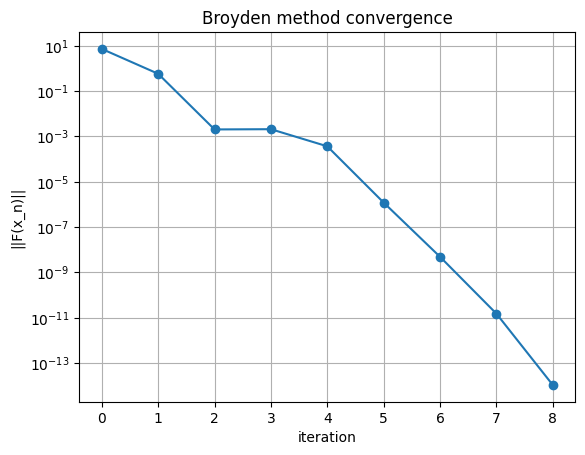


=== (d) Symmetric update on gradient system ===
x* = [-2.22044605e-15  3.55271368e-15]
||∇f(x*)|| = 8.379058453350832e-15


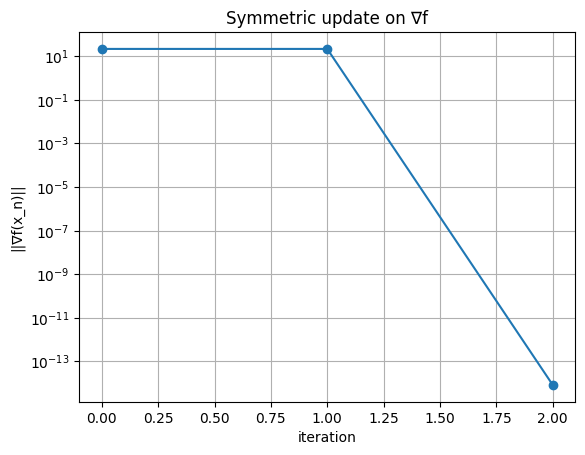

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Exercise 10.3 — Quasi-Newton methods
# ============================================================

# ------------------------------------------------------------
# (a) Quasi-Newton updates
# ------------------------------------------------------------

def broyden_update(H, s, y):
    """
    Classical Broyden rank-1 update:
    H_{n+1} = H_n + (y - H_n s) s^T / ||s||^2
    """
    s = np.asarray(s, float)
    y = np.asarray(y, float)
    denom = s @ s
    if denom == 0:
        return H.copy()
    return H + np.outer(y - H @ s, s) / denom


def symmetric_update(H, s, y):
    """
    Symmetric update from the exercise (eq. (3)):
    H_{n+1} = H_n + (u s^T + s u^T)/||s||^2 - (u^T s / ||s||^4) s s^T,
    where u = y - H_n s.
    """
    s = np.asarray(s, float)
    y = np.asarray(y, float)
    denom = s @ s
    if denom == 0:
        return H.copy()
    u = y - H @ s
    return (H
            + (np.outer(u, s) + np.outer(s, u)) / denom
            - (u @ s) / (denom**2) * np.outer(s, s))


# ------------------------------------------------------------
# Generic quasi-Newton solver
# ------------------------------------------------------------

def quasi_newton(F, x0, H0, update="broyden", maxit=50, tol=1e-12):
    """
    Solve F(x)=0 using a quasi-Newton method.
    """
    x = np.asarray(x0, float)
    H = np.asarray(H0, float).copy()

    update_fun = broyden_update if update == "broyden" else symmetric_update

    Fx_norm = []

    for k in range(maxit):
        Fx = np.asarray(F(x), float)
        Fx_norm.append(np.linalg.norm(Fx))

        if Fx_norm[-1] < tol:
            break

        dx = -np.linalg.pinv(H) @ Fx
        x_new = x + dx

        s = x_new - x
        y = np.asarray(F(x_new), float) - Fx

        H = update_fun(H, s, y)
        x = x_new

    return x, H, np.array(Fx_norm)


# ------------------------------------------------------------
# (b) Test Broyden method on given F
# ------------------------------------------------------------

def F_example(x):
    x1, x2 = x
    return np.array([
        (x1 + 3) * (x2**3 - 7) + 18,
        np.sin(x2 * np.exp(x1) - 1)
    ])

def DF_example(x):
    x1, x2 = x
    df1_dx1 = x2**3 - 7
    df1_dx2 = (x1 + 3) * 3 * x2**2
    arg = x2 * np.exp(x1) - 1
    df2_dx1 = np.cos(arg) * (x2 * np.exp(x1))
    df2_dx2 = np.cos(arg) * np.exp(x1)
    return np.array([[df1_dx1, df1_dx2],
                     [df2_dx1, df2_dx2]])

x0 = np.array([-0.5, 1.4])
H0 = DF_example(x0)

x_star, H_star, hist_broyden = quasi_newton(
    F_example, x0, H0, update="broyden"
)

print("=== (b) Broyden method ===")
print("x* =", x_star)
print("||F(x*)|| =", np.linalg.norm(F_example(x_star)))

plt.figure()
plt.semilogy(hist_broyden, marker="o")
plt.xlabel("iteration")
plt.ylabel("||F(x_n)||")
plt.title("Broyden method convergence")
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# (c) Symmetry proof (theoretical)
# ------------------------------------------------------------
# If H_n is symmetric:
#  - u s^T + s u^T is symmetric
#  - s s^T is symmetric
# Hence H_{n+1} is symmetric.


# ------------------------------------------------------------
# (d) Minimization via F = ∇f
# ------------------------------------------------------------

def grad_f(x):
    return np.array([2*x[0], 2*x[1]])

x0 = np.array([4.0, 10.0])
H0 = np.eye(2)   # symmetric initial approximation

x_star, H_star, hist_sym = quasi_newton(
    grad_f, x0, H0, update="symmetric"
)

print("\n=== (d) Symmetric update on gradient system ===")
print("x* =", x_star)
print("||∇f(x*)|| =", np.linalg.norm(grad_f(x_star)))

plt.figure()
plt.semilogy(hist_sym, marker="o")
plt.xlabel("iteration")
plt.ylabel("||∇f(x_n)||")
plt.title("Symmetric update on ∇f")
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# (e) Explanation
# ------------------------------------------------------------
# The symmetric update forces H_n to remain symmetric.
# This is suitable when F = ∇f (Jacobian = Hessian, symmetric),
# but can be problematic for general F, whose Jacobian need not
# be symmetric, so H_n cannot converge to DF(x*).